<a href="https://colab.research.google.com/github/urazovandriy-dotcom/ML_LABS_2026/blob/main/%D0%9B%D0%A06_%D0%A3%D1%80%D0%B0%D0%B7%D0%BE%D0%B2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

**Був присутній на парі.**

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

Завантажити датасет з Kaggle (Google Colab)

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [3]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [5]:
df['gender'].value_counts()

,count
gender,
Female,58552
Male,41430
Other,18


In [6]:
df['smoking_history'].value_counts()

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [7]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [8]:
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [9]:
df['diabetes'].value_counts()


,count
diabetes,
0,91500
1,8500


Висновок: спостерігається суттєвий дисбаланс класів — спостереження без діабету (клас 0) становлять приблизно 91.5%, тоді як пацієнти з діабетом (клас 1) складають лише близько 8.5%.

Перевірити наявність пропущених даних


In [10]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [11]:
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [12]:
df.drop_duplicates(inplace=True)

In [13]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [14]:
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

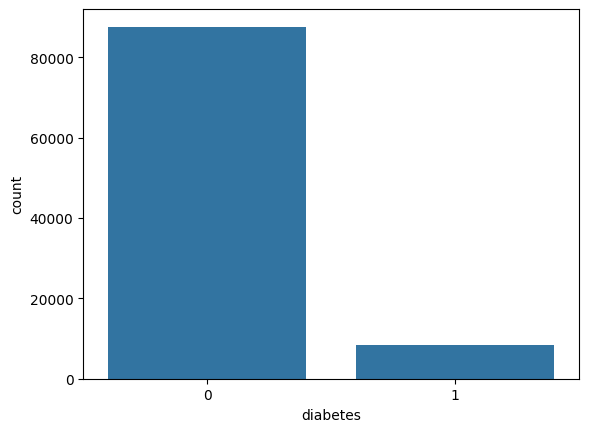

In [15]:
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [16]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [17]:
X = df.drop(columns=['diabetes'])
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}, y_test shape:  {y_test.shape}")

X_train shape: (76916, 8), y_train shape: (76916,)
X_test shape:  (19230, 8), y_test shape:  (19230,)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [18]:
X_train = pd.get_dummies(X_train, columns=['gender', 'smoking_history'])
X_test = pd.get_dummies(X_test, columns=['gender', 'smoking_history'])
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [19]:
display(X_train.describe().round(3))

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
count,76916.000,76916.000,76916.000,76916.000,76916.000,76916.000
mean,41.761,0.078,0.041,27.314,5.531,138.114
std,22.468,0.268,0.198,6.757,1.072,40.897
min,0.080,0.000,0.000,10.010,3.500,80.000
25%,24.000,0.000,0.000,23.390,4.800,100.000
50%,43.000,0.000,0.000,27.320,5.800,140.000
75%,59.000,0.000,0.000,29.850,6.200,159.000
max,80.000,1.000,1.000,95.220,9.000,300.000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [20]:
target_corr = X_train.apply(lambda col: col.corr(y_train))
target_corr_sorted = pd.DataFrame({
    'Кореляція (r)': target_corr,
    'Модуль (|r|)': target_corr.abs()
}).sort_values(by='Модуль (|r|)', ascending=False)
print("Кореляція ознак із y_train:")
display(target_corr_sorted)

Кореляція ознак із y_train:


,Кореляція (r),Модуль (|r|)
blood_glucose_level,0.423011,0.423011
HbA1c_level,0.405321,0.405321
age,0.266649,0.266649
bmi,0.213456,0.213456
hypertension,0.199069,0.199069
heart_disease,0.174470,0.174470
smoking_history_No Info,-0.113053,0.113053
smoking_history_former,0.096162,0.096162
gender_Male,0.040650,0.040650
gender_Female,-0.040533,0.040533


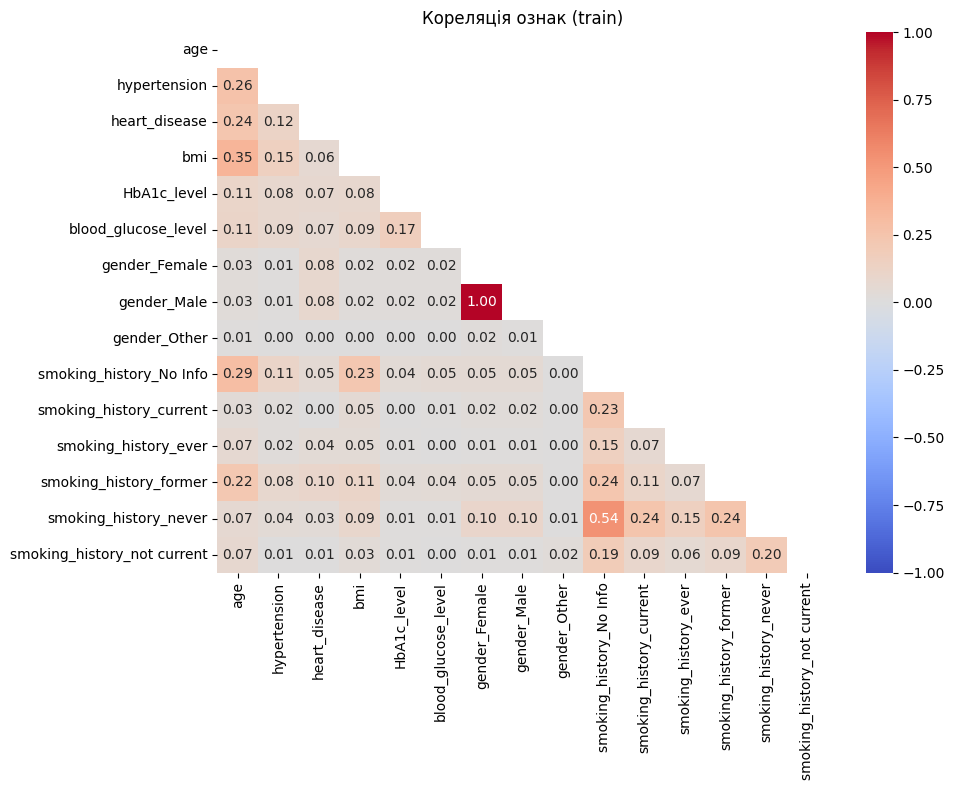

In [21]:
mtx = X_train.corr(numeric_only=True).abs()
plt.figure(figsize=(10, 8))
sns.heatmap(mtx, cmap='coolwarm', annot=True, fmt='.2f',
    mask=np.triu(np.ones_like(mtx, dtype=bool)),
    vmin=-1, vmax=1)
plt.title('Кореляція ознак (train)')
plt.tight_layout()
plt.show()

**Висновок:**


**Кореляція між ознаками:** сильна залежність спостерігається лише між `gender_Female` та `gender_Male` ($\vert{}r\vert{} = 1.00$) через взаємовиключне бінарне кодування статі (пастка фіктивних змінних). Серед числових ознак найбільший зв'язок мають `age` та `bmi` ($\vert{}r\vert{} = 0.35$), а між рештою показників кореляція слабка ($\vert{}r\vert{} < 0.30$).


**Зв'язок із цільовою змінною (`diabetes`):** найсильніше з діабетом корелюють рівень глюкози (`blood_glucose_level`) та глікований гемоглобін (`HbA1c_level`), помірно — вік (`age`) та `bmi`.


**Чи потрібно видаляти ознаки:** ні, видаляти клінічні ознаки не потрібно. Сильна мультиколінеарність серед числових даних відсутня ($\vert{}r\vert{} \le 0.35$), а дублювання категорій статі нівелюється регуляризацією моделей або параметром `drop_first=True`. Кожен показник несе унікальну інформацію для класифікації.

Перевірити викиди **лише на навчальній вибірці**

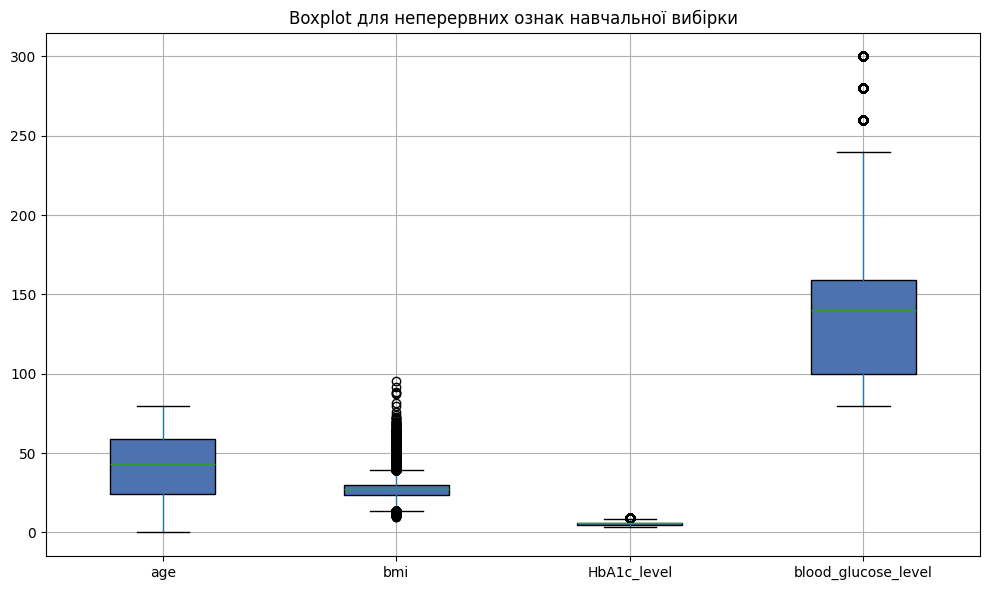

In [23]:
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
plt.figure(figsize=(10, 6))
X_train[continuous_cols].boxplot(rot=0, patch_artist=True, boxprops=dict(facecolor='#4c72b0', color='black'))
plt.title('Boxplot для неперервних ознак навчальної вибірки')
plt.tight_layout()
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

Перевірити асиметрію розподілів ознак **на train**

In [24]:
skewness = X_train[continuous_cols].skew()
display(skewness.round(4))

,0
age,-0.0615
bmi,1.0050
HbA1c_level,-0.0557
blood_glucose_level,0.8308


In [28]:
print(f"Пропуски в train: {X_train.isnull().sum().sum()}")
print(f"Пропуски в test:  {X_test.isnull().sum().sum()}")

Пропуски в train: 0
Пропуски в test:  0


**Проміжний висновок:**

**Баланс класів:** у тренувальній вибірці присутній виражений дисбаланс — міноритарний клас пацієнтів із діабетом складає лише близько $8.5\%$, тоді як здорових спостережень — $91.5\%$. Стратифікація (stratify=y) дозволила зберегти цю пропорцію незмінною в обох вибірках.

**Кореляції:** найвищий лінійний зв'язок із цільовою змінною мають рівень глюкози (blood_glucose_level) та глікований гемоглобін (HbA1c_level). Між самими ознаками небезпечної мультиколінеарності немає ($\vert{}r\vert{} \le 0.35$ для числових показників), а сильна залежність виникає лише між дублюючими One-Hot категоріями статі.

**Викиди та асиметрія:** показники age ($-0.0615$) та HbA1c_level ($-0.0557$) мають симетричний розподіл, тоді як для bmi ($1.0050$) та blood_glucose_level ($0.8308$) зафіксовано правосторонню асиметрію та довгі «хвости» екстремальних значень на діаграмі розмаху. Викиди не вилучалися, оскільки високі рівні глюкози та індексу маси тіла є клінічно важливими патологічними ознаками діабету.

**Якість даних:** у вибірках X_train та X_test повністю відсутні пропущені значення ($0$ пропусків). Тестова вибірка залишається недоторканою до етапу фінальної оцінки моделей.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [29]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [34]:

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)
print("ДО балансування:")
print(pd.Series(y_train).value_counts())
print("\nПІСЛЯ балансування (SMOTE):")
print(pd.Series(y_train_balanced).value_counts())

ДО балансування:
diabetes
0    70130
1     6786
Name: count, dtype: int64

ПІСЛЯ балансування (SMOTE):
diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [35]:
models = {
    'LogisticRegression': LogisticRegression(random_state=42, max_iter=1000),
    'RidgeClassifier': RidgeClassifier(random_state=42),
    'SGDClassifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



=== LogisticRegression ===
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



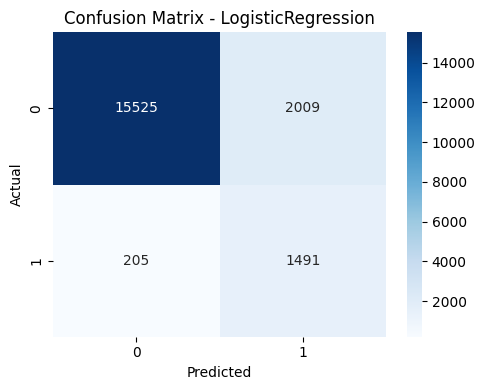


=== RidgeClassifier ===
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



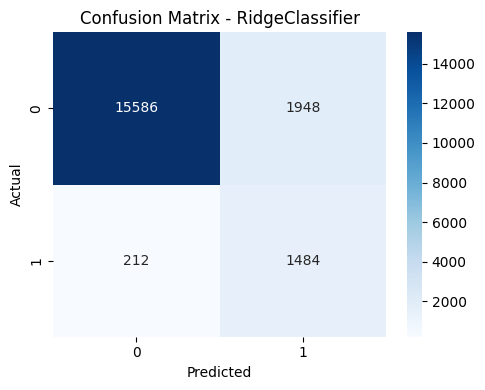


=== SGDClassifier ===
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



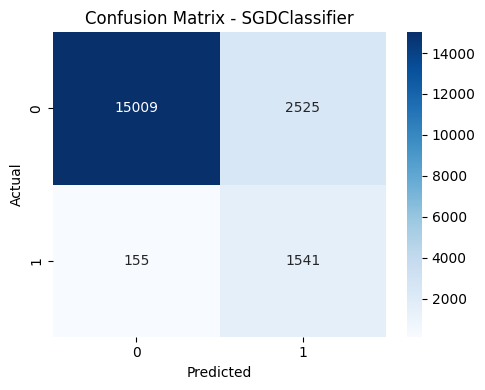


=== SVC ===
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



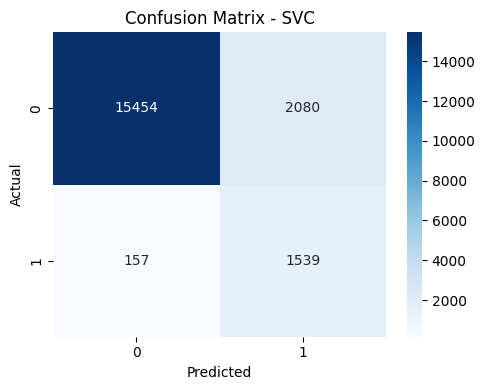

In [36]:
for name, model in models.items():
    model.fit(X_train_balanced, y_train_balanced)
    predictions = model.predict(X_test_scaled)

    print(f"\n=== {name} ===")
    print(classification_report(y_test, predictions, zero_division=0))

    cm = confusion_matrix(y_test, predictions)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()

Оптимізувати гіперпараметри


In [37]:
param_grids = {
    'LogisticRegression': {
        'C': [0.01, 0.1, 1, 10],
        'solver': ['lbfgs', 'liblinear']
    },
    'RidgeClassifier': {
        'alpha': [0.1, 1.0, 10.0]
    },
    'SGDClassifier': {
        'loss': ['log_loss', 'hinge'],
        'alpha': [0.0001, 0.001, 0.01],
        'penalty': ['l2', 'l1']
    },
    'SVC': {
        'C': [0.1, 1, 10],
        'kernel': ['linear', 'rbf']
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [38]:

from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [39]:
best_models = {}
best_scores = {}
for name, model in models.items():
    print(f"\nПідбір параметрів для {name}...")
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])
    params = {'model__' + key: values for key, values in param_grids[name].items()}
    search = HalvingGridSearchCV(
        pipeline, params, scoring='f1', cv=3, factor=2,
        min_resources=300, random_state=42, n_jobs=1
    )
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print('Найкращі параметри:', search.best_params_)
    print(f'F1 на кросвалідації: {search.best_score_:.3f}')
    predictions = search.best_estimator_.predict(X_test)
    print('Класифікаційний звіт на test:')
    print(classification_report(y_test, predictions, zero_division=0))


Підбір параметрів для LogisticRegression...
Найкращі параметри: {'model__C': 0.01, 'model__solver': 'lbfgs'}
F1 на кросвалідації: 0.653
Класифікаційний звіт на test:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.89      0.90     19230


Підбір параметрів для RidgeClassifier...
Найкращі параметри: {'model__alpha': 10.0}
F1 на кросвалідації: 0.571
Класифікаційний звіт на test:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230


Підбір параметрів для SGDClassifier.

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [40]:
best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]

print(f"Найкраща модель за F1 на CV: {best_model_name}")
print(f"Середній F1 на CV: {best_scores[best_model_name]:.4f}")

Найкраща модель за F1 на CV: LogisticRegression
Середній F1 на CV: 0.6530


In [41]:
sample_test = X_test.sample(n=10, random_state=42)
sample_indices = sample_test.index
true_classes = y_test.loc[sample_indices].values
predicted_classes = best_model.predict(sample_test)

predictions_comparison_df = pd.DataFrame({
    'Індекс': sample_indices,
    'Істинний клас': true_classes,
    'Передбачений клас': predicted_classes
}).reset_index(drop=True)

display(predictions_comparison_df)

,Індекс,Істинний клас,Передбачений клас
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


**Підсумкові висновки:**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?

Дисбаланс: у вибірці спостерігався різкий дисбаланс класів — міноритарний цільовий клас diabetes = 1 склав лише близько $8.8\%$ (1696 випадків у тесті проти 17534 здорових).   Кореляція: найбільший лінійний зв'язок із діабетом виявлено у медичних показників blood_glucose_level ($r \approx 0.42$) та HbA1c_level ($r \approx 0.40$); між собою числові ознаки не мали мультиколінеарності ($\vert{}r\vert{} \le 0.35$).   Викиди: діаграми розмаху та показники асиметрії виявили помітні «хвости» екстремальних значень у bmi ($1.0050$) та blood_glucose_level ($0.8308$). Їх не видаляли, оскільки в медичному контексті аномально високий цукор та індекс маси тіла є ключовими симптомами хвороби, а не помилками вимірювання.

2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?

На відкладеному тесті найвищий recall ($0.91$) для хворого класу продемонстрували SVC та SGDClassifier (пропустили найменше хворих пацієнтів), а F1-score ($0.57\dots0.58$) був практично однаковим для всіх моделей через низький precision (~$0.42\dots0.43$), спричинений генерацією синтетичних прикладів SMOTE.   За результатами крос-валідації (HalvingGridSearchCV) найкращою моделлю стала LogisticRegression із середнім показником F1 = 0.6530 (проти 0.648 у SGD, 0.622 у SVC та 0.571 у Ridge).

3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?

Оптимальні параметри:

* LogisticRegression: {'C': 0.01, 'solver': 'lbfgs'}.   

* RidgeClassifier: {'alpha': 10.0}.   

* SGDClassifier: {'alpha': 0.01, 'loss': 'log_loss', 'penalty': 'l1'}.   SVC: {'C': 1, 'kernel': 'linear'}.   

Структура помилок: у всіх моделей хибнопозитивних результатів (False Positives, ~1950–2520) суттєво більше, ніж хибнонегативних (False Negatives, ~155–212). Оскільки моделі навчалися на збалансованій SMOTE вибірці, вони стали набагато чутливішими до класу діабету. Для медичної діагностики це виправданий компроміс: краще відправити здорового пацієнта на повторний аналіз (FP), ніж пропустити реальну хворобу (FN).

4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

Тестова вибірка повинна залишатися недоторканою, щоб об'єктивно імітувати роботу алгоритму в реальних умовах на нових, невідомих раніше пацієнтах із природним співвідношенням класів.   Якщо застосувати StandardScaler або синтез прикладів SMOTE до всієї вибірки одразу, виникне витік даних (data leakage): параметри розподілу тесту (середнє, дисперсія) або згенеровані на його основі штучні точки потраплять у навчання. Завдяки Pipeline на кожному згині крос-валідації SMOTE та масштабування навчалися суто на тренувальних згинах, гарантуючи повну валідність експерименту.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

In [42]:
!pip install -q catboost

In [43]:
import re
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

In [44]:
clean_columns = [re.sub(r'[ ,:\(\)\[\]<>]', '_', col) for col in X_train.columns]
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()
X_train_clean.columns = clean_columns
X_test_clean.columns = clean_columns

In [45]:
boosting_models = {
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1),
    'CatBoost': CatBoostClassifier(random_state=42, verbose=0)
}


========================= XGBoost =========================
              precision    recall  f1-score   support

           0     0.9719    0.9967    0.9841     17534
           1     0.9543    0.7017    0.8087      1696

    accuracy                         0.9707     19230
   macro avg     0.9631    0.8492    0.8964     19230
weighted avg     0.9703    0.9707    0.9687     19230


========================= LightGBM =========================
              precision    recall  f1-score   support

           0     0.9713    0.9986    0.9848     17534
           1     0.9800    0.6946    0.8130      1696

    accuracy                         0.9718     19230
   macro avg     0.9757    0.8466    0.8989     19230
weighted avg     0.9720    0.9718    0.9696     19230


========================= CatBoost =========================
              precision    recall  f1-score   support

           0     0.9718    0.9966    0.9841     17534
           1     0.9527    0.7011    0.8077      169

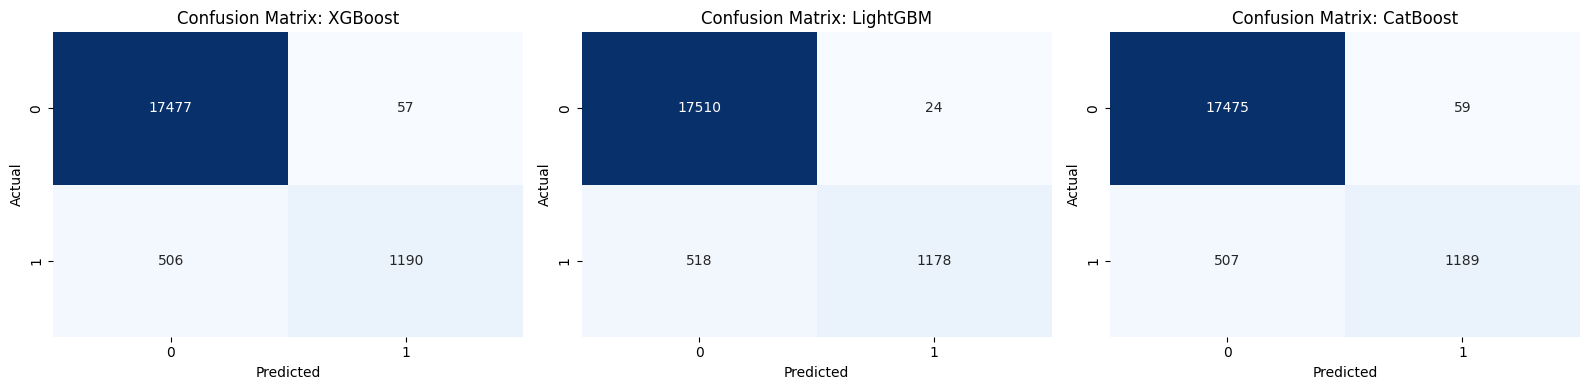

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for idx, (name, model) in enumerate(boosting_models.items()):
    model.fit(X_train_clean, y_train)
    y_pred = model.predict(X_test_clean)

    print(f"\n{'='*25} {name} {'='*25}")
    print(classification_report(y_test, y_pred, digits=4))

    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f'Confusion Matrix: {name}')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

plt.tight_layout()
plt.show()

### Висновки(додаткове завдання):

**Порівняння метрик моделей бустингу:**
* **LightGBM** продемонстрував найвищу загальну точність (**Accuracy = 0.9718**) та найкращий баланс **F1-score = 0.8130** для класу хворих на діабет (`1`). Модель досягла виняткової точності передбачення позитивного класу (**Precision = 0.9800**).

* **XGBoost** показав схожі високі результати: **Accuracy = 0.9707**, **F1-score = 0.8087**, **Precision = 0.9543** та дещо вищий **Recall = 0.7017**.

* **CatBoost** досяг практично ідентичних до XGBoost показників: **Accuracy = 0.9706**, **F1-score = 0.8077**, **Precision = 0.9527**, **Recall = 0.7011**.


**Аналіз матриць плутанини та помилок:**
* Кількість хибнопозитивних спрацьовувань (**False Positives**) різко скоротилася порівняно з лінійними моделями: всього **24** у LightGBM, **57** у XGBoost та **59** у CatBoost (проти ~2000 у логістичної регресії).

* Водночас кількість хибнонегативних випадків (**False Negatives**) зросла до **506–518** (Recall становить ~70%). Це означає, що моделі бустингу за стандартного порогу класифікації $0.5$ діють значно обережніше та видають діагноз «діабет» лише за високої впевненості.


**Загальний підсумок:** алгоритми градієнтного бустингу суттєво перевершили базові лінійні класифікатори за гармонійною метрикою **F1-score** (зростання з **0.57** до **0.81**) та загальною точністю **Accuracy** (зростання з **0.88** до **0.97**). Вони ефективно виявили складні нелінійні залежності між глюкозою, HbA1c та іншими факторами ризику без обов'язкового попереднього масштабування та штучного оверсемплінгу даних. Для практичного застосування в медицині баланс між Precision та Recall у цих моделей можна додатково оптимізувати зниженням порогу ймовірності класифікації (threshold tuning).